In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df_achi = pd.read_excel('Particle_size_substrates.xlsx', sheet_name='a-chitin', skiprows = 2)
df_bchi = pd.read_excel('Particle_size_substrates.xlsx', sheet_name='b-chitin', skiprows = 2)
df_cnc = pd.read_excel('Particle_size_substrates.xlsx', sheet_name='CNC', skiprows = 2)
df_cnf = pd.read_excel('Particle_size_substrates.xlsx', sheet_name='CNF', skiprows = 2)

In [3]:
def plot_size(df, ax, title):
    ax.plot(df['Size Classes (μm)'], df['Volume Density (%)'])
    ax.plot(df['Size Classes (μm).1'], df['Volume Density (%).1'])
    ax.plot(df['Size Classes (μm).2'], df['Volume Density (%).2'])
    ax.plot(df['Size Classes (μm).3'], df['Volume Density (%).3'])
    ax.plot(df['Size Classes (μm).4'], df['Volume Density (%).4'])
    ax.set_title(title)
    
    

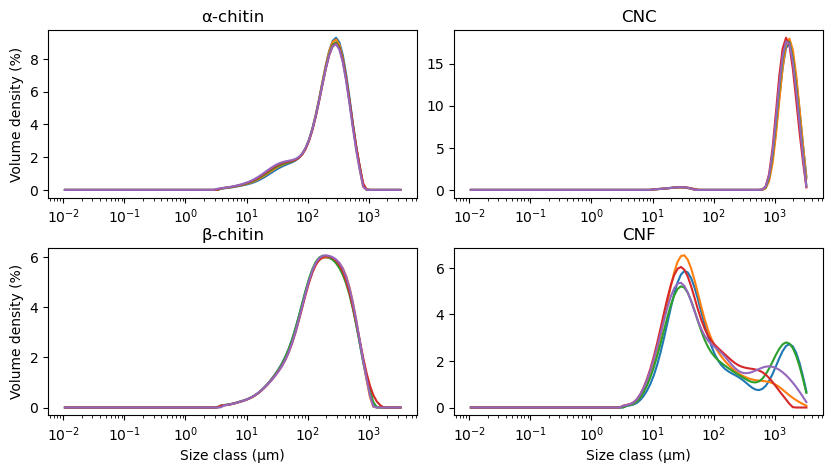

In [20]:
fig, ax = plt.subplots(2,2, figsize=(10,5), sharex = False)
plt.subplots_adjust(wspace = 0.1)
plt.subplots_adjust(hspace = 0.3)

plot_size(df_achi, ax[0,0], 'α-chitin')
plot_size(df_bchi, ax[1,0], 'β-chitin')

plot_size(df_cnc, ax[0,1], 'CNC')
plot_size(df_cnf, ax[1,1], 'CNF')

#ax[0,1].axvline(x=100, color='red', linestyle='--', linewidth=2)
#ax[1,1].axvline(x=500, color='red', linestyle='--', linewidth=2)

ax[0,0].set_xscale('log')
ax[0,1].set_xscale('log')
ax[1,0].set_xscale('log')
ax[1,1].set_xscale('log')



ax[0,0].set_ylabel('Volume density (%)')
ax[1,0].set_ylabel('Volume density (%)')
ax[1,0].set_xlabel('Size class (μm)')
ax[1,1].set_xlabel('Size class (μm)')

plt.savefig('particle_size.svg', bbox_inches = 'tight')

In [14]:
def particle_stats(df, size_col, volume_col, density):
    
    d = df[size_col].to_numpy()
    q = df[volume_col].to_numpy()

    # Remove NaNs and zero-density points
    mask = (~np.isnan(d)) & (~np.isnan(q)) & (q > 0)
    d = d[mask]
    q = q[mask]

    logd = np.log10(d)

    # Total volume
    I0 = np.trapezoid(q, x=logd)

    # Mean diameters
    D43 = np.trapezoid(d * q, x=logd) / I0
    D32 = I0 / np.trapezoid(q / d, x=logd)

    # Specific surface area
    SSA = 6*1000 / (density * D32)

    # Cumulative volume distribution
    dx = np.diff(logd)
    areas = 0.5 * (q[:-1] + q[1:]) * dx

    cumulative = np.concatenate([[0], np.cumsum(areas)])
    cumulative = cumulative / cumulative[-1] * 100

    # Percentiles
    Dv10 = 10 ** np.interp(10, cumulative, logd)
    Dv50 = 10 ** np.interp(50, cumulative, logd)
    Dv90 = 10 ** np.interp(90, cumulative, logd)

    # Span
    span = (Dv90 - Dv10) / Dv50

    return {
        'D[4,3] (µm)': D43,
        'D[3,2] (µm)': D32,
        'Dv10 (µm)': Dv10,
        'Dv50 (µm)': Dv50,
        'Dv90 (µm)': Dv90,
        'Span': span,
        'SSA (m²/kg)': SSA,
        'Volume integral': I0
    }

In [15]:
def particle_stats_replicates(df, density, n=5):

    results = []

    for i in range(n):

        # First measurement has no suffix
        if i == 0:
            size_col = 'Size Classes (μm)'
            volume_col = 'Volume Density (%)'

        # Subsequent measurements have .1, .2, .3, ...
        else:
            size_col = f'Size Classes (μm).{i}'
            volume_col = f'Volume Density (%).{i}'

        stats = particle_stats(
            df,
            size_col=size_col,
            volume_col=volume_col,
            density=density
        )

        results.append(stats)

    # Convert results into dataframe
    results = pd.DataFrame(results)

    # Name rows
    results.index = [
        f'Measurement {i+1}' for i in range(n)
    ]

    return results

In [16]:
df = df_achi
print('a-chitin:')

results = particle_stats_replicates(df, density=1.425)

print(results)

summary = pd.DataFrame({
    'Mean': results.mean(),
    'SD': results.std()
})

print(summary)

a-chitin:
               D[4,3] (µm)  D[3,2] (µm)  Dv10 (µm)   Dv50 (µm)   Dv90 (µm)  \
Measurement 1   248.233250    95.953592  45.104021  227.693902  475.298193   
Measurement 2   242.743282    90.753864  41.137523  222.774768  468.563879   
Measurement 3   243.188293    88.146416  38.961977  221.827245  473.384067   
Measurement 4   242.495891    85.521127  36.954788  220.918638  474.737731   
Measurement 5   236.242619    81.363571  34.957416  215.759367  464.405587   

                   Span  SSA (m²/kg)  Volume integral  
Measurement 1  1.889353    43.880862         6.650049  
Measurement 2  1.918648    46.395009         6.649995  
Measurement 3  1.958380    47.767413         6.650000  
Measurement 4  1.981648    49.233756         6.650007  
Measurement 5  1.990403    51.749527         6.649995  
                       Mean        SD
D[4,3] (µm)      242.580667  4.258092
D[3,2] (µm)       88.347714  5.487424
Dv10 (µm)         39.423145  3.919810
Dv50 (µm)        221.794784  4.27

In [17]:
df = df_bchi
print('b-chitin:')

results = particle_stats_replicates(df, density=1.425)

print(results)

summary = pd.DataFrame({
    'Mean': results.mean(),
    'SD': results.std()
})

print(summary)

b-chitin:
               D[4,3] (µm)  D[3,2] (µm)  Dv10 (µm)   Dv50 (µm)   Dv90 (µm)  \
Measurement 1   241.994828    86.141809  41.483189  177.364837  541.682961   
Measurement 2   244.023655    87.981856  42.454159  181.032157  543.982733   
Measurement 3   244.161444    87.255300  42.169243  177.282728  548.187843   
Measurement 4   255.816219    89.397283  43.113547  184.447136  571.373898   
Measurement 5   245.569963    89.938715  43.159037  182.347653  546.301363   

                   Span  SSA (m²/kg)  Volume integral  
Measurement 1  2.820174    48.879009         6.650008  
Measurement 2  2.770384    47.856757         6.650017  
Measurement 3  2.854303    48.255250         6.650032  
Measurement 4  2.864020    47.099041         6.650007  
Measurement 5  2.759248    46.815505         6.650024  
                       Mean         SD
D[4,3] (µm)      246.313222   5.463062
D[3,2] (µm)       88.142993   1.550529
Dv10 (µm)         42.475835   0.698795
Dv50 (µm)        180.494902  

In [18]:
df = df_cnc
density = 1.60

print('CNC')

results = particle_stats_replicates(df, density)
print(results)
summary = pd.DataFrame({'Mean': results.mean(),'SD': results.std()})
print(summary)

print('')
print('Split data for two size distributions:')
small = df[df['Size Classes (μm)'] < 100]
large = df[df['Size Classes (μm)'] >= 100]

print('\nSmall population')
results = particle_stats_replicates(small, density)
print(results)
summary = pd.DataFrame({'Mean': results.mean(),'SD': results.std()})
print(summary)

print('\nLarge population')
results = particle_stats_replicates(large, density)
print(results)
summary = pd.DataFrame({'Mean': results.mean(),'SD': results.std()})
print(summary)



CNC
               D[4,3] (µm)  D[3,2] (µm)    Dv10 (µm)    Dv50 (µm)  \
Measurement 1  1707.362446   643.907259  1052.420523  1657.470811   
Measurement 2  1720.555081   655.620011  1072.098585  1674.173851   
Measurement 3  1654.523165   640.021262  1030.925266  1606.356127   
Measurement 4  1596.867410   623.420227   995.196628  1544.125348   
Measurement 5  1637.153790   643.049854  1016.068292  1586.245559   

                 Dv90 (µm)      Span  SSA (m²/kg)  Volume integral  
Measurement 1  2513.435277  0.881472     5.823820         6.600411  
Measurement 2  2511.333193  0.859669     5.719777         6.607882  
Measurement 3  2438.612684  0.876323     5.859180         6.634528  
Measurement 4  2360.613403  0.884266     6.015204         6.641755  
Measurement 5  2418.928277  0.884390     5.831585         6.639175  
                        Mean         SD
D[4,3] (µm)      1663.292378  50.974477
D[3,2] (µm)       641.203723  11.577971
Dv10 (µm)        1033.341859  30.105456
Dv50 (µ

In [19]:
df = df_cnf
density = 1.60

print('CNF')

results = particle_stats_replicates(df, density)
print(results)
summary = pd.DataFrame({'Mean': results.mean(),'SD': results.std()})
print(summary)

print('')
print('Split data for two size distributions:')
small = df[df['Size Classes (μm)'] < 500]
large = df[df['Size Classes (μm)'] >= 500]

print('\nSmall population')
results = particle_stats_replicates(small, density)
print(results)
summary = pd.DataFrame({'Mean': results.mean(),'SD': results.std()})
print(summary)

print('\nLarge population')
results = particle_stats_replicates(large, density)
print(results)
summary = pd.DataFrame({'Mean': results.mean(),'SD': results.std()})
print(summary)



CNF
               D[4,3] (µm)  D[3,2] (µm)  Dv10 (µm)  Dv50 (µm)    Dv90 (µm)  \
Measurement 1   395.311261    38.772587  16.493168  54.502944  1573.967544   
Measurement 2   164.305336    32.056950  14.533594  43.076775   438.774347   
Measurement 3   415.024160    37.512220  15.129659  58.680540  1544.746006   
Measurement 4   143.672439    30.907738  13.570265  43.255983   426.576243   
Measurement 5   266.652788    33.407764  13.841236  50.956393   885.507154   

                    Span  SSA (m²/kg)  Volume integral  
Measurement 1  28.575968    96.717817         6.627770  
Measurement 2   9.848480   116.979315         6.647614  
Measurement 3  26.066842    99.967425         6.629672  
Measurement 4   9.547950   121.328842         6.649989  
Measurement 5  17.106115   112.249355         6.642517  
                       Mean          SD
D[4,3] (µm)      276.993197  126.126537
D[3,2] (µm)       34.531452    3.441996
Dv10 (µm)         14.713585    1.166255
Dv50 (µm)         50.0945